# MTI850 – Projet final A26 : Livrable partiel 1
**Demande et rééquilibrage du réseau BIXI à Montréal** — Fortin Laurine, Beaugeois Carole, Elfassi Ethan

### 1. Présentation du problème et description des données
- **Problème :** Prédire la demande horaire (départs/arrivées) par station BIXI pour optimiser le rééquilibrage des vélos.
- **Pertinence Big Data :** >30–40M de trajets historiques (Go), jointures multi-sources (trajets, stations, météo, calendrier).
- **Sources :** [BIXI Open Data](https://bixi.com/en/open-data/) | [Portail Montréal](https://donnees.montreal.ca/group/transport?organization=bixi) | **URL téléchargement :** `<TODO: Ajouter lien Google Drive / OneDrive>`

In [1]:
import os
import findspark
findspark.init("/opt/spark")

from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.types import StructType, StructField, StringType, DoubleType, LongType
from pyspark.sql.window import Window
from pyspark.ml.feature import StringIndexer, VectorAssembler
import matplotlib.pyplot as plt
import seaborn as sns

# Sous-échantillonnage pour exécution rapide (mettre à 1.0 pour toutes les données)
SAMPLE_FRACTION = 0.02

# Chemins des données (détection automatique selon le répertoire de travail)
TRIPS_PATH = "data/bixi_trips_2026.csv" if os.path.exists("data/bixi_trips_2026.csv") else "mti-850/data/bixi_trips_2026.csv"
RAIN_PATH = "data/pluviometrie_25-27.csv" if os.path.exists("data/pluviometrie_25-27.csv") else "mti-850/data/pluviometrie_25-27.csv"
HDFS_RAW_PATH = "hdfs:///user/mti850/bixi/raw_trips"
HDFS_RAIN_RAW_PATH = "hdfs:///user/mti850/bixi/raw_rain"
OUTPUT_PARQUET_PATH = "df_features.parquet"
HDFS_OUTPUT_PARQUET_PATH = "hdfs:///user/mti850/bixi/df_features.parquet"

### 2. Ingestion de données

In [2]:
spark = SparkSession.builder \
    .master("local[*]") \
    .appName("MTI850 - BIXI Montreal - Livrable 1") \
    .config("spark.driver.memory", "2g") \
    .config("spark.sql.shuffle.partitions", "8") \
    .config("spark.sql.adaptive.enabled", "true") \
    .getOrCreate()

spark.sparkContext.setLogLevel("WARN")
print(f"Spark version: {spark.version}")

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/11/19 14:55:41 WARN Utils: Your hostname, mti850-VirtualBox, resolves to a loopback address: 127.0.1.1; using 10.0.2.15 instead (on interface enp0s3)
26/11/19 14:55:41 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
/opt/spark/python/pyspark/testing/utils.py:127: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
26/11/19 14:55:46 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Spark version: 4.2.0


In [3]:
bixi_schema = StructType([
    StructField("STARTSTATIONNAME", StringType(), True),
    StructField("STARTSTATIONARRONDISSEMENT", StringType(), True),
    StructField("STARTSTATIONLATITUDE", DoubleType(), True),
    StructField("STARTSTATIONLONGITUDE", DoubleType(), True),
    StructField("ENDSTATIONNAME", StringType(), True),
    StructField("ENDSTATIONARRONDISSEMENT", StringType(), True),
    StructField("ENDSTATIONLATITUDE", DoubleType(), True),
    StructField("ENDSTATIONLONGITUDE", DoubleType(), True),
    StructField("STARTTIMEMS", LongType(), True),
    StructField("ENDTIMEMS", LongType(), True),
])

df_raw = spark.read.csv(TRIPS_PATH, header=True, schema=bixi_schema)
if SAMPLE_FRACTION < 1.0:
    df_raw = df_raw.sample(withReplacement=False, fraction=SAMPLE_FRACTION, seed=42)
df_raw = df_raw.cache()

df_raw.printSchema()
df_raw.show(5, truncate=False)
print(f"Nombre total de lignes chargées (fraction={SAMPLE_FRACTION}) : {df_raw.count():,}")

root
 |-- STARTSTATIONNAME: string (nullable = true)
 |-- STARTSTATIONARRONDISSEMENT: string (nullable = true)
 |-- STARTSTATIONLATITUDE: double (nullable = true)
 |-- STARTSTATIONLONGITUDE: double (nullable = true)
 |-- ENDSTATIONNAME: string (nullable = true)
 |-- ENDSTATIONARRONDISSEMENT: string (nullable = true)
 |-- ENDSTATIONLATITUDE: double (nullable = true)
 |-- ENDSTATIONLONGITUDE: double (nullable = true)
 |-- STARTTIMEMS: long (nullable = true)
 |-- ENDTIMEMS: long (nullable = true)



+-------------------------------------+-------------------------------------+--------------------+---------------------+-----------------------------------------+-------------------------------------+------------------+-------------------+-------------+-------------+
|STARTSTATIONNAME                     |STARTSTATIONARRONDISSEMENT           |STARTSTATIONLATITUDE|STARTSTATIONLONGITUDE|ENDSTATIONNAME                           |ENDSTATIONARRONDISSEMENT             |ENDSTATIONLATITUDE|ENDSTATIONLONGITUDE|STARTTIMEMS  |ENDTIMEMS    |
+-------------------------------------+-------------------------------------+--------------------+---------------------+-----------------------------------------+-------------------------------------+------------------+-------------------+-------------+-------------+
|Duluth / de l'Esplanade              |Le Plateau-Mont-Royal                |45.515132275425785  |-73.58105599880219   |de Maisonneuve / de Bleury               |Ville-Marie                       

Nombre total de lignes chargées (fraction=0.02) : 190,244


In [4]:
# Optionnel : sauvegarde brute dans HDFS
# df_raw.write.mode("overwrite").parquet(HDFS_RAW_PATH)

### 3. Nettoyage et prétraitement des données

In [5]:
# Valeurs manquantes par colonne
null_counts = df_raw.select([
    F.count(F.when(F.col(c).isNull(), c)).alias(c) for c in df_raw.columns
])
null_counts.show(vertical=True)

# Suppression des doublons et des trajets sans station ou horodatage
df_clean = df_raw.dropDuplicates().dropna(subset=[
    "STARTSTATIONNAME", "ENDSTATIONNAME", "STARTTIMEMS", "ENDTIMEMS"
])

-RECORD 0-------------------------
 STARTSTATIONNAME           | 0   
 STARTSTATIONARRONDISSEMENT | 0   
 STARTSTATIONLATITUDE       | 0   
 STARTSTATIONLONGITUDE      | 0   
 ENDSTATIONNAME             | 873 
 ENDSTATIONARRONDISSEMENT   | 886 
 ENDSTATIONLATITUDE         | 873 
 ENDSTATIONLONGITUDE        | 873 
 STARTTIMEMS                | 0   
 ENDTIMEMS                  | 873 



In [6]:
# Conversion des timestamps (millisecondes -> timestamp) et calcul de la durée en secondes
df_clean = df_clean \
    .withColumn("start_ts", (F.col("STARTTIMEMS").cast("double") / 1000.0).cast("timestamp")) \
    .withColumn("end_ts", (F.col("ENDTIMEMS").cast("double") / 1000.0).cast("timestamp")) \
    .withColumn("duration_sec", F.col("end_ts").cast("long") - F.col("start_ts").cast("long"))

# Normalisation des textes (trim)
df_clean = df_clean \
    .withColumn("STARTSTATIONNAME", F.trim(F.col("STARTSTATIONNAME"))) \
    .withColumn("ENDSTATIONNAME", F.trim(F.col("ENDSTATIONNAME"))) \
    .withColumn("STARTSTATIONARRONDISSEMENT", F.trim(F.col("STARTSTATIONARRONDISSEMENT")))

# Filtrage des valeurs aberrantes (durée entre 60s et 24h, coordonnées valides autour de Montréal)
df_clean = df_clean.filter(
    (F.col("duration_sec").between(60, 86400)) &
    (F.col("STARTSTATIONLATITUDE").between(45.3, 45.8)) &
    (F.col("STARTSTATIONLONGITUDE").between(-74.0, -73.3))
)

# Imputation des arrondissements manquants
df_clean = df_clean.na.fill({"STARTSTATIONARRONDISSEMENT": "Inconnu", "ENDSTATIONARRONDISSEMENT": "Inconnu"})

print(f"Lignes après nettoyage : {df_clean.count():,}")
df_clean.select("STARTSTATIONNAME", "ENDSTATIONNAME", "start_ts", "end_ts", "duration_sec").show(5, truncate=False)

Lignes après nettoyage : 186,692


+---------------------------------------------+--------------------------------------------+-----------------------+-----------------------+------------+
|STARTSTATIONNAME                             |ENDSTATIONNAME                              |start_ts               |end_ts                 |duration_sec|
+---------------------------------------------+--------------------------------------------+-----------------------+-----------------------+------------+
|de Monkland / Girouard                       |Métro Villa-Maria (de Monkland / Décarie)   |2026-03-16 12:11:38.801|2026-03-16 12:13:26.423|108         |
|Parc Beaubien Outremont (Stuart / St-Viateur)|Métro Berri-UQAM (St-Denis / de Maisonneuve)|2026-03-16 11:55:56.457|2026-03-16 12:18:27.331|1351        |
|Parthenais / du Mont-Royal                   |Métro Mont-Royal (Place Gérald-Godin)       |2026-03-16 08:18:34.841|2026-03-16 08:26:14.414|460         |
|Roy / St-André                               |de Maisonneuve / Mackay      

In [7]:
# Chargement et agrégation horaire de la pluviométrie (1 impulsion = 0.2 mm, STATUT == 0 valide)
rain_schema = StructType([
    StructField("NO_SICOS", StringType(), True),
    StructField("DATE", StringType(), True),
    StructField("IMPULSION", LongType(), True),
    StructField("STATUT", LongType(), True),
])

df_rain_raw = spark.read.csv(RAIN_PATH, header=True, schema=rain_schema)

# Optionnel : sauvegarde brute de la pluviométrie dans HDFS
# df_rain_raw.write.mode("overwrite").parquet(HDFS_RAIN_RAW_PATH)

df_rain_hourly = df_rain_raw \
    .filter((F.col("STATUT") == 0) & (F.col("IMPULSION") > 0)) \
    .withColumn("rain_ts", F.to_timestamp("DATE", "yyyy-MM-dd HH:mm:ss")) \
    .withColumn("hour_ts", F.date_trunc("hour", "rain_ts")) \
    .groupBy("NO_SICOS", "hour_ts") \
    .agg((F.sum("IMPULSION") * 0.2).alias("station_rain_mm")) \
    .groupBy("hour_ts") \
    .agg(
        F.round(F.avg("station_rain_mm"), 3).alias("rain_mm"),
        F.count("*").alias("active_rain_gauges")
    ) \
    .withColumn("is_raining", F.lit(1))

print(f"Heures avec pluie enregistrée : {df_rain_hourly.count():,}")
df_rain_hourly.orderBy(F.desc("rain_mm")).show(5, truncate=False)

Heures avec pluie enregistrée : 3,217


+-------------------+-------+------------------+----------+
|hour_ts            |rain_mm|active_rain_gauges|is_raining|
+-------------------+-------+------------------+----------+
|2026-06-20 18:00:00|58.667 |6                 |1         |
|2026-05-29 20:00:00|51.673 |33                |1         |
|2026-05-29 22:00:00|51.328 |39                |1         |
|2026-06-18 09:00:00|50.771 |14                |1         |
|2026-05-29 21:00:00|50.642 |38                |1         |
+-------------------+-------+------------------+----------+
only showing top 5 rows


### 4. Analyse exploratoire des données (EDA)

/opt/spark/python/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


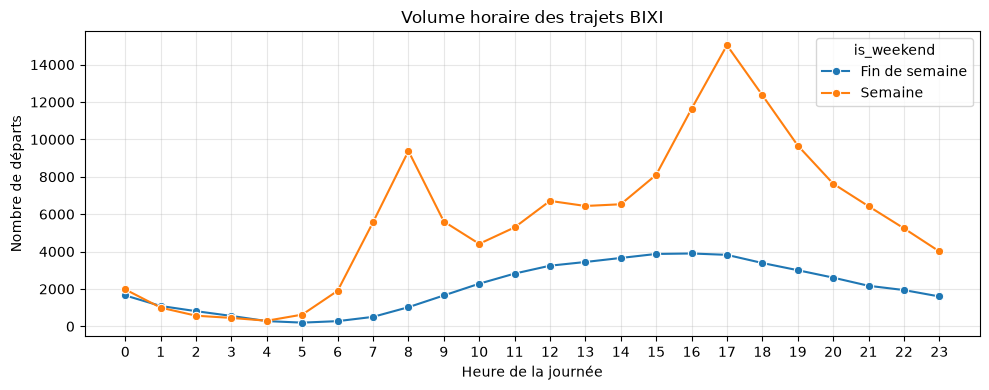

/opt/spark/python/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/tmp/ipykernel_13586/3640266119.py:24: FutureWarning:                           

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_stations_pd, y="STARTSTATIONNAME", x="count", palette="viridis")


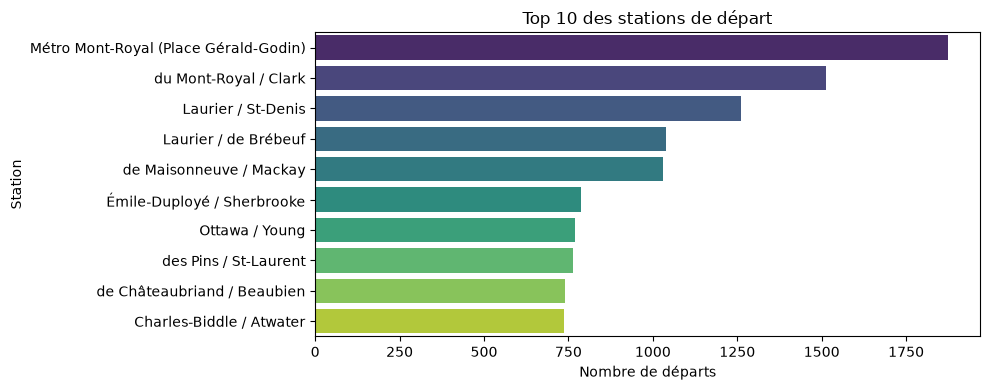

In [8]:
df_eda = df_clean \
    .withColumn("hour", F.hour("start_ts")) \
    .withColumn("day_of_week", F.dayofweek("start_ts")) \
    .withColumn("is_weekend", F.when(F.col("day_of_week").isin(1, 7), "Fin de semaine").otherwise("Semaine"))

# 1. Demande horaire (Semaine vs Fin de semaine)
hourly_pd = df_eda.groupBy("hour", "is_weekend").count().orderBy("hour").toPandas()

plt.figure(figsize=(10, 4))
sns.lineplot(data=hourly_pd, x="hour", y="count", hue="is_weekend", marker="o")
plt.title("Volume horaire des trajets BIXI")
plt.xlabel("Heure de la journée")
plt.ylabel("Nombre de départs")
plt.xticks(range(0, 24))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 2. Top 10 des stations de départ
top_stations_pd = df_eda.groupBy("STARTSTATIONNAME").count() \
    .orderBy(F.desc("count")).limit(10).toPandas()

plt.figure(figsize=(10, 4))
sns.barplot(data=top_stations_pd, y="STARTSTATIONNAME", x="count", palette="viridis")
plt.title("Top 10 des stations de départ")
plt.xlabel("Nombre de départs")
plt.ylabel("Station")
plt.tight_layout()
plt.show()

/opt/spark/python/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


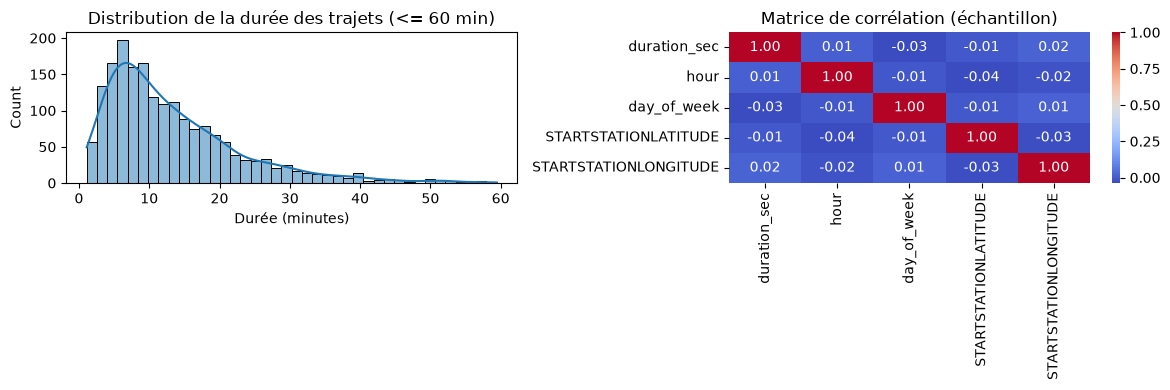

In [9]:
# 3. Distribution de la durée des trajets (échantillon)
sample_pd = df_eda.select("duration_sec", "hour", "day_of_week", "STARTSTATIONLATITUDE", "STARTSTATIONLONGITUDE") \
    .sample(withReplacement=False, fraction=0.01, seed=42).limit(5000).toPandas()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(sample_pd[sample_pd["duration_sec"] <= 3600]["duration_sec"] / 60, bins=40, kde=True, ax=axes[0])
axes[0].set_title("Distribution de la durée des trajets (<= 60 min)")
axes[0].set_xlabel("Durée (minutes)")

sns.heatmap(sample_pd.corr(numeric_only=True), annot=True, fmt=".2f", cmap="coolwarm", ax=axes[1])
axes[1].set_title("Matrice de corrélation (échantillon)")
plt.tight_layout()
plt.show()

/opt/spark/python/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/opt/spark/python/pyspark/sql/pandas/types.py:778: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


                             nb_heures  trajets_moy_heure  duree_moy_min
rain_category                                                           
1. Aucune pluie (0 mm)            2552              29.60          14.58
2. Pluie légère (<= 1 mm/h)        650               9.22          14.04
3. Pluie modérée (1-5 mm/h)        212              33.80          14.46
4. Pluie forte (> 5 mm/h)          141              30.97          12.88


/tmp/ipykernel_13586/2073438166.py:45: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=hourly_rain_pd, x="rain_category", y="trips_per_hour", order=order_cats, palette="Blues_d", ax=axes[1])


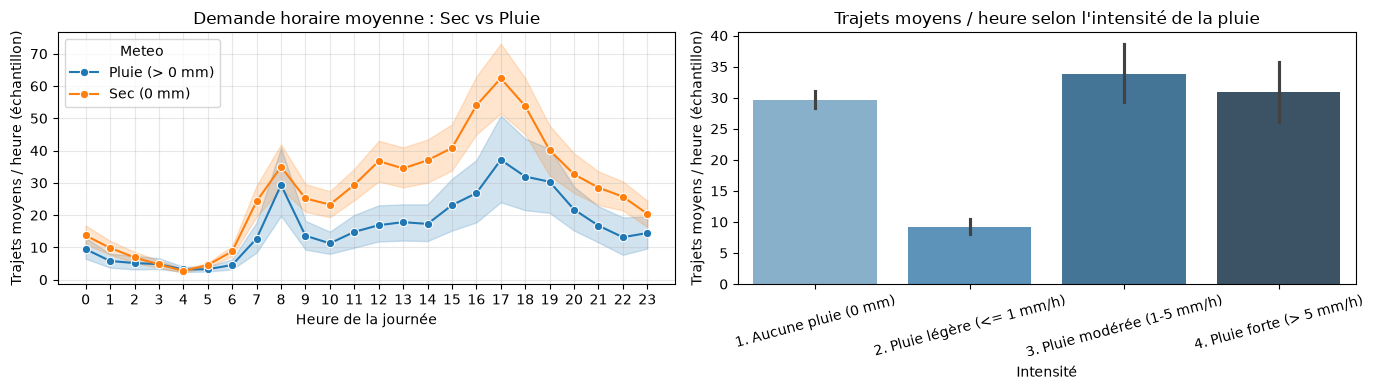

In [10]:
# 4. Comparaison de l'utilisation BIXI en fonction de la pluie
max_rain_ts = df_rain_hourly.agg(F.max("hour_ts")).collect()[0][0]

df_trips_rain = df_clean \
    .withColumn("hour_ts", F.date_trunc("hour", "start_ts")) \
    .filter(F.col("hour_ts") <= F.lit(max_rain_ts)) \
    .join(df_rain_hourly, on="hour_ts", how="left") \
    .na.fill({"rain_mm": 0.0, "is_raining": 0}) \
    .withColumn("hour", F.hour("hour_ts")) \
    .withColumn(
        "rain_category",
        F.when(F.col("rain_mm") == 0, "1. Aucune pluie (0 mm)")
         .when(F.col("rain_mm") <= 1.0, "2. Pluie légère (<= 1 mm/h)")
         .when(F.col("rain_mm") <= 5.0, "3. Pluie modérée (1-5 mm/h)")
         .otherwise("4. Pluie forte (> 5 mm/h)")
    )

# Agrégation par heure exacte pour comparer la moyenne de trajets/heure (sec vs pluie)
hourly_rain_pd = df_trips_rain \
    .groupBy("hour_ts", "hour", "is_raining", "rain_category") \
    .agg(
        F.count("*").alias("trips_per_hour"),
        F.avg(F.col("duration_sec") / 60.0).alias("avg_duration_min")
    ).toPandas()

hourly_rain_pd["Meteo"] = hourly_rain_pd["is_raining"].map({0: "Sec (0 mm)", 1: "Pluie (> 0 mm)"})

summary_rain = hourly_rain_pd.groupby("rain_category").agg(
    nb_heures=("hour_ts", "count"),
    trajets_moy_heure=("trips_per_hour", "mean"),
    duree_moy_min=("avg_duration_min", "mean")
).round(2)
print(summary_rain)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.lineplot(data=hourly_rain_pd, x="hour", y="trips_per_hour", hue="Meteo", marker="o", ax=axes[0])
axes[0].set_title("Demande horaire moyenne : Sec vs Pluie")
axes[0].set_xlabel("Heure de la journée")
axes[0].set_ylabel("Trajets moyens / heure (échantillon)")
axes[0].set_xticks(range(0, 24))
axes[0].grid(alpha=0.3)

order_cats = sorted(hourly_rain_pd["rain_category"].unique())
sns.barplot(data=hourly_rain_pd, x="rain_category", y="trips_per_hour", order=order_cats, palette="Blues_d", ax=axes[1])
axes[1].set_title("Trajets moyens / heure selon l'intensité de la pluie")
axes[1].set_xlabel("Intensité")
axes[1].set_ylabel("Trajets moyens / heure (échantillon)")
axes[1].tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.show()

### 5. Sélection des caractéristiques et ingénierie

In [11]:
# Agrégation horaire des départs par station
departures = df_clean \
    .withColumn("hour_ts", F.date_trunc("hour", "start_ts")) \
    .groupBy(
        F.col("STARTSTATIONNAME").alias("station_name"),
        F.col("STARTSTATIONARRONDISSEMENT").alias("arrondissement"),
        "hour_ts"
    ).agg(
        F.count("*").alias("departures"),
        F.avg("duration_sec").alias("avg_duration_sec"),
        F.first("STARTSTATIONLATITUDE").alias("latitude"),
        F.first("STARTSTATIONLONGITUDE").alias("longitude")
    )

# Agrégation horaire des arrivées par station
arrivals = df_clean \
    .withColumn("hour_ts", F.date_trunc("hour", "end_ts")) \
    .groupBy(F.col("ENDSTATIONNAME").alias("station_name"), "hour_ts") \
    .agg(F.count("*").alias("arrivals"))

# Jointure départs + arrivées + pluviométrie horaire et calcul du flux net
df_hourly = departures.join(arrivals, on=["station_name", "hour_ts"], how="left") \
    .join(df_rain_hourly.select("hour_ts", "rain_mm", "is_raining"), on="hour_ts", how="left") \
    .na.fill({"arrivals": 0, "rain_mm": 0.0, "is_raining": 0}) \
    .withColumn("net_flow", F.col("arrivals") - F.col("departures"))

In [12]:
# Variables temporelles
df_hourly = df_hourly \
    .withColumn("hour", F.hour("hour_ts")) \
    .withColumn("day_of_week", F.dayofweek("hour_ts")) \
    .withColumn("month", F.month("hour_ts")) \
    .withColumn("is_weekend", F.when(F.col("day_of_week").isin(1, 7), 1).otherwise(0))

# Variables décalées (lag 1h et 24h par station)
w_station = Window.partitionBy("station_name").orderBy("hour_ts")

df_hourly = df_hourly \
    .withColumn("lag_1h_departures", F.lag("departures", 1).over(w_station)) \
    .withColumn("lag_1h_arrivals", F.lag("arrivals", 1).over(w_station)) \
    .withColumn("lag_24h_departures", F.lag("departures", 24).over(w_station)) \
    .na.fill({"lag_1h_departures": 0, "lag_1h_arrivals": 0, "lag_24h_departures": 0})

In [13]:
# Encodage des variables catégorielles
station_indexer = StringIndexer(inputCol="station_name", outputCol="station_idx", handleInvalid="keep")
arr_indexer = StringIndexer(inputCol="arrondissement", outputCol="arrondissement_idx", handleInvalid="keep")

df_indexed = station_indexer.fit(df_hourly).transform(df_hourly)
df_indexed = arr_indexer.fit(df_indexed).transform(df_indexed)

# Assemblage du vecteur de caractéristiques
feature_cols = [
    "station_idx", "arrondissement_idx",
    "latitude", "longitude",
    "hour", "day_of_week", "month", "is_weekend",
    "avg_duration_sec",
    "rain_mm", "is_raining",
    "lag_1h_departures", "lag_1h_arrivals", "lag_24h_departures"
]

assembler = VectorAssembler(inputCols=feature_cols, outputCol="features", handleInvalid="skip")
df_features = assembler.transform(df_indexed)

df_features.select("station_name", "hour_ts", "departures", "arrivals", "net_flow", "features").show(5, truncate=False)

26/11/19 15:01:14 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


+----------------------+-------------------+----------+--------+--------+-------------------------------------------------------------------------------------------+
|station_name          |hour_ts            |departures|arrivals|net_flow|features                                                                                   |
+----------------------+-------------------+----------+--------+--------+-------------------------------------------------------------------------------------------+
|16e avenue / St-Joseph|2026-04-09 07:00:00|1         |0       |-1      |[526.0,2.0,45.55293611277267,-73.56577143073082,7.0,5.0,4.0,0.0,765.0,0.0,0.0,0.0,0.0,0.0] |
|16e avenue / St-Joseph|2026-04-13 08:00:00|1         |0       |-1      |[526.0,2.0,45.55293611277267,-73.56577143073082,8.0,2.0,4.0,0.0,281.0,0.2,1.0,1.0,0.0,0.0] |
|16e avenue / St-Joseph|2026-04-16 08:00:00|1         |0       |-1      |[526.0,2.0,45.55293611277267,-73.56577143073082,8.0,5.0,4.0,0.0,504.0,0.2,1.0,1.0,0.0,0.0] |
|16e

### 6. Sauvegarder les données préparées

In [14]:
# Sauvegarde locale en Parquet
df_features.write.mode("overwrite").parquet(OUTPUT_PARQUET_PATH)

# Sauvegarde HDFS (à décommenter sur le cluster)
# df_features.write.mode("overwrite").parquet(HDFS_OUTPUT_PARQUET_PATH)

# Vérification
df_check = spark.read.parquet(OUTPUT_PARQUET_PATH)
print(f"Parquet sauvegardé : {df_check.count():,} lignes, {len(df_check.columns)} colonnes")
df_check.printSchema()

Parquet sauvegardé : 171,993 lignes, 21 colonnes
root
 |-- hour_ts: timestamp (nullable = true)
 |-- station_name: string (nullable = true)
 |-- arrondissement: string (nullable = true)
 |-- departures: long (nullable = true)
 |-- avg_duration_sec: double (nullable = true)
 |-- latitude: double (nullable = true)
 |-- longitude: double (nullable = true)
 |-- arrivals: long (nullable = true)
 |-- rain_mm: double (nullable = true)
 |-- is_raining: integer (nullable = true)
 |-- net_flow: long (nullable = true)
 |-- hour: integer (nullable = true)
 |-- day_of_week: integer (nullable = true)
 |-- month: integer (nullable = true)
 |-- is_weekend: integer (nullable = true)
 |-- lag_1h_departures: long (nullable = true)
 |-- lag_1h_arrivals: long (nullable = true)
 |-- lag_24h_departures: long (nullable = true)
 |-- station_idx: double (nullable = true)
 |-- arrondissement_idx: double (nullable = true)
 |-- features: vector (nullable = true)

